# Discrete Flow Matching for *De Novo* Peptide Sequencing
### A Hands-On Tutorial & Interactive Guide

Welcome to the interactive tutorial for **Discrete Flow Matching (DFM)** applied to *de novo* peptide sequencing from tandem mass spectrometry (MS/MS) data.

Unlike traditional autoregressive methods (e.g., Casanovo, DeepNovo) that decode amino acids left-to-right token by token ($\mathcal{O}(N)$ serial forward passes), Discrete Flow Matching formulates sequence generation as a continuous-time probability velocity field over discrete categorical simplices. By combining non-autoregressive velocity flow with Knapsack dynamic programming and Classifier-Free Guidance (CFG), DFM decodes complete full-length peptide sequences in **a fixed number of steps ($T \approx 25$)**, delivering **10× to 40× higher throughput** while matching or exceeding state-of-the-art accuracy.

#### What You Will Learn in This Tutorial:
1. **Load Pretrained Models:** Inspect and initialize pretrained DFM checkpoints (Nine-Species benchmark fine-tuned, MassIVE-KB 28M foundation, and HCPT synthetic pretrained).
2. **Configure Decoding Hyperparameters:** Explore how classifier-free guidance scale ($\gamma$), Knapsack dynamic programming mass filters, and candidate length beam size ($L$) govern inference accuracy and fidelity.
3. **Load Benchmark Data:** Dynamically stream and subsample the Nine-Species held-out test dataset (`InstaDeepAI/ms_ninespecies_benchmark`). You can select your desired sample size (e.g., 200 spectra for instant preview, 1,000 for standard analysis, or more).
4. **Optional Fine-Tuning:** Learn how to fine-tune the model for 2 epochs on custom datasets using PyTorch Lightning.
5. **Run Inference & Compute Quantitative Metrics:** Evaluate amino acid precision, recall, F1, exact sequence accuracy, I/L-conflated match, and length accuracy directly on your evaluated batch.
6. **Plot Dynamic Visualizations:** Render publication-grade figures (length-stratified accuracy, experimental fragment mirror plots, confidence calibration, and mass error distributions) computed directly from your own run.

## 1. Environment & Hardware Initialization
First, verify hardware acceleration (NVIDIA GPU) and import core libraries.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import time
from pathlib import Path
from typing import List, Dict, Tuple, Optional

# Auto-detect repository root directory
candidate_roots = [Path.cwd().resolve(), Path.cwd().resolve().parent, Path('/home/joelgedeon_aims_ac_za/dfm-joelresearch').resolve()]
repo_root = next((p for p in candidate_roots if (p / 'src').exists()), Path.cwd().resolve())

for p in [str(repo_root), str(repo_root / "src")]:
    if p not in sys.path:
        sys.path.insert(0, p)

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# DFM core modules
from data.constants import AA_MASSES_DICT, M_H, M_H2O
from data.data import get_dataset, build_vocabulary, invert_vocabulary, parse_peptide, build_dataloader
from train.factory import build_models
from train.io import load_checkpoint, load_models_from_checkpoint, infer_model_config_from_checkpoint
from flow_matching.scheduler import cosine_scheduler, linear_scheduler, sigmoid_scheduler
from eval.evaluate import evaluate_generative
from eval.metrics import compute_denovo_metrics

# Set deterministic random seeds
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Environment initialized successfully:")
print(f"  PyTorch Version:  {torch.__version__}")
print(f"  Execution Device: {device} " + (f"({torch.cuda.get_device_name(0)})" if device.type == 'cuda' else "(CPU Mode)"))
print(f"  Repository Root:  {repo_root}")

Environment initialized successfully:
  PyTorch Version:  2.14.0+cu130
  Execution Device: cuda (NVIDIA H100 80GB HBM3)
  Repository Root:  /home/joelgedeon_aims_ac_za/dfm-joelresearch


## 2. Interactive Model Selector & Checkpoint Loader
Select which pretrained checkpoint you would like to test:
- **Nine-Species Fine-Tuned:** Fine-tuned with balanced multispecies loss on held-out eukaryotic and bacterial organisms.
- **MassIVE-KB 28M Foundation:** Trained on 28+ million natural human peptidome spectra with max sequence length 50.
- **HCPT Pretrained:** Pretrained on synthetic high-coverage ProteomeTools library.

In [2]:
# Select model checkpoint (Options: 'Nine-Species Fine-Tuned', 'MassIVE-KB 28M Foundation', 'HCPT Pretrained')
SELECTED_MODEL = "Nine-Species Fine-Tuned"

CHECKPOINT_REGISTRY = {
    "Nine-Species Fine-Tuned": repo_root / "artifacts/dfm_joint_balanced_30ep/checkpoints/dfm_balanced_best.ckpt",
    "MassIVE-KB 28M Foundation": repo_root / "artifacts/massive_kb_run/dfm_massive_kb_full_28m_length50_h100/checkpoints/best-exact-epoch=02-exact=0.5199.ckpt",
    "HCPT Pretrained": repo_root / "artifacts/canonical_reproduction/stage3_stratified/checkpoints/best-hcpt-stratified-epoch=04-exact=0.3799.ckpt",
}

ckpt_path = CHECKPOINT_REGISTRY[SELECTED_MODEL]
assert ckpt_path.exists(), f"Checkpoint not found at: {ckpt_path}"
print(f"Loading checkpoint: {ckpt_path.relative_to(repo_root)}")

# Load checkpoint payload onto device
ckpt = load_checkpoint(ckpt_path, map_location=device)
vocab = ckpt.get("vocabulary") or build_vocabulary(include_ptms=True)
inv_vocab = invert_vocabulary(vocab)

# Infer architecture and build models
model_cfg = infer_model_config_from_checkpoint(ckpt)
print(f"Inferred model architecture: {model_cfg}")

spectrum_encoder, length_predictor, decoder, guidance = build_models(
    vocab, device=device, model_cfg=model_cfg, compile_models=False
)
load_models_from_checkpoint(ckpt, spectrum_encoder, length_predictor, decoder, guidance, use_ema=True)

# Set evaluation mode
spectrum_encoder.eval()
length_predictor.eval()
decoder.eval()
guidance.eval()

def count_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())

total_params = count_params(spectrum_encoder) + count_params(length_predictor) + count_params(decoder) + count_params(guidance)
print(f"\n{SELECTED_MODEL} successfully loaded:")
print(f"  Spectrum Encoder:   {count_params(spectrum_encoder):,} parameters")
print(f"  Length Predictor:   {count_params(length_predictor):,} parameters")
print(f"  Peptide Decoder:    {count_params(decoder):,} parameters")
print(f"  CFG Guidance Head:  {count_params(guidance):,} parameters")
print(f"  Total Parameters:   {total_params:,} (~{total_params/1e6:.1f}M)")
print(f"  Vocabulary Size:    {len(vocab)} tokens")

Loading checkpoint: artifacts/dfm_joint_balanced_30ep/checkpoints/dfm_balanced_best.ckpt


Inferred model architecture: {'encoder_layers': 6, 'decoder_blocks': 6, 'model_dim': 512, 'encoder_ff_dim': 1536, 'max_length': 30, 'min_length': 1}


/home/joelgedeon_aims_ac_za/dfm-joelresearch/src/model/model.py:42: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)



Nine-Species Fine-Tuned successfully loaded:
  Spectrum Encoder:   16,293,888 parameters
  Length Predictor:   346,270 parameters
  Peptide Decoder:    42,834,974 parameters
  CFG Guidance Head:  512 parameters
  Total Parameters:   59,475,644 (~59.5M)
  Vocabulary Size:    32 tokens


## 3. Inference & Decoding Hyperparameters
Discrete Flow Matching enables fine-grained control over decoding parameters:
- `top_k_lengths`: Number of top length hypotheses evaluated in parallel beam search.
- `guidance_scale`: Classifier-Free Guidance strength $\gamma$. Higher values enhance fidelity to peaks.
- `use_exact_dp_knapsack`: Enforces strict prefix/suffix mass reachability using $O(W)$ dynamic programming.
- `inference_steps`: Number of Euler integration steps ($T$) along the probability trajectory.
- `scheduler`: Noise schedule function (`cosine`, `linear`, `sigmoid`).

In [3]:
DECODING_CONFIG = {
    "top_k_lengths": 3,             # Top candidate peptide lengths to test
    "guidance_scale": 1.8,          # Classifier-Free Guidance scale (gamma)
    "use_exact_dp_knapsack": True,  # Filter token transitions via Knapsack DP
    "knapsack_tol_da": 1.0,         # Mass tolerance window for Knapsack DP in Daltons
    "inference_steps": 25,          # Number of Euler integration steps (T)
    "scheduler": "cosine",          # Noise trajectory schedule: 'cosine', 'linear', 'sigmoid'
    "batch_size": 64,               # Batch size for evaluation DataLoader
}

SCHEDULER_REGISTRY = {
    "cosine": cosine_scheduler,
    "linear": linear_scheduler,
    "sigmoid": sigmoid_scheduler,
}
active_scheduler = SCHEDULER_REGISTRY[DECODING_CONFIG["scheduler"]]

print("Active Decoding Parameters:")
for k, v in DECODING_CONFIG.items():
    print(f"  {k:24s}: {v}")

Active Decoding Parameters:
  top_k_lengths           : 3
  guidance_scale          : 1.8
  use_exact_dp_knapsack   : True
  knapsack_tol_da         : 1.0
  inference_steps         : 25
  scheduler               : cosine
  batch_size              : 64


## 4. Load the Nine-Species Benchmark Dataset
We use the standard codebase loader `get_dataset` to load the official Nine-Species test set (`InstaDeepAI/ms_ninespecies_benchmark`).

You can adjust `NUM_SPECTRA` below to choose how many spectra to evaluate:
- `NUM_SPECTRA = 200`: Quick demo (~4-5 seconds on GPU)
- `NUM_SPECTRA = 1000`: Standard evaluation (~20 seconds on GPU)
- `NUM_SPECTRA = 10000`: Deep statistical benchmark (~3 minutes on GPU)

In [4]:
# Choose the number of spectra to evaluate (e.g., 200 for fast tutorial, 1000 for standard run)
NUM_SPECTRA = 200

print(f"Loading Nine-Species test split from local cache...")
cache_dir = repo_root / "data/cache"
full_test_dataset = get_dataset(
    "InstaDeepAI/ms_ninespecies_benchmark",
    split="test",
    cache_dir=str(cache_dir)
)
print(f"Full benchmark test split contains {len(full_test_dataset):,} spectra.")

# Subsample to the user-specified sample size
if NUM_SPECTRA is not None and NUM_SPECTRA < len(full_test_dataset):
    eval_dataset = full_test_dataset.select(range(NUM_SPECTRA))
else:
    eval_dataset = full_test_dataset

print(f"Subsampled evaluation slice: {len(eval_dataset):,} spectra")

# Build PyTorch DataLoader using codebase build_dataloader
eval_loader = build_dataloader(
    eval_dataset,
    vocab=vocab,
    batch_size=DECODING_CONFIG["batch_size"],
    shuffle=False,
    is_train=False,
)

# Preview first 3 spectra
print("\nFirst 3 sample spectra:")
for i in range(min(3, len(eval_dataset))):
    s = eval_dataset[i]
    print(f"  [{i+1}] Target: {s['sequence']:<18s} | Precursor Mass: {s['precursor_mass']:.2f} Da | z={s['precursor_charge']}+ | Peaks: {len(s['mz_array'])}")

Loading Nine-Species test split from local cache...


Full benchmark test split contains 111,029 spectra.
Subsampled evaluation slice: 200 spectra

First 3 sample spectra:
  [1] Target: IVSWYDNEYGYSTR     | Precursor Mass: 1751.78 Da | z=2+ | Peaks: 86
  [2] Target: TFFVGGNFK          | Precursor Mass: 1015.51 Da | z=2+ | Peaks: 35
  [3] Target: ISVQDIDIK          | Precursor Mass: 1029.57 Da | z=2+ | Peaks: 33


## 5. Optional Fine-Tuning / Training (Default: 2 Epochs)
This cell illustrates how to execute fine-tuning using PyTorch Lightning. Set `DO_TRAIN = True` if you wish to run 2 fine-tuning epochs.

In [5]:
DO_TRAIN = False  # Set to True to execute fine-tuning

if DO_TRAIN:
    import pytorch_lightning as pl
    from train.lightning import DFMLightningModule
    
    train_subset = full_test_dataset.select(range(500))
    train_loader = build_dataloader(train_subset, vocab=vocab, batch_size=32, shuffle=True, is_train=True)
    
    model_module = DFMLightningModule(
        spectrum_encoder=spectrum_encoder,
        length_predictor=length_predictor,
        decoder=decoder,
        guidance_head=guidance,
        vocabulary=vocab,
        learning_rate=5e-5,
    )
    
    trainer = pl.Trainer(
        max_epochs=2,
        accelerator="gpu" if torch.cuda.is_available() else "cpu",
        devices=1,
        precision="16-mixed" if torch.cuda.is_available() else 32,
        log_every_n_steps=10,
    )
    
    print("Starting 2 epochs of fine-tuning...")
    trainer.fit(model_module, train_dataloaders=train_loader)
    print("Fine-tuning complete.")
else:
    print("Skipping training (DO_TRAIN = False). Proceeding directly to inference.")

Skipping training (DO_TRAIN = False). Proceeding directly to inference.


## 6. Run De Novo Peptide Sequencing Inference
We execute non-autoregressive discrete flow matching over the loaded spectra using `evaluate_generative` from the codebase.
All predictions, exact matches, mass matches, scores, and lengths are collected dynamically.

In [6]:
print(f"Executing de novo sequencing on {len(eval_dataset)} spectra...")
t_start = time.perf_counter()

metrics, details = evaluate_generative(
    loader=eval_loader,
    vocabulary=vocab,
    spectrum_encoder=spectrum_encoder,
    length_predictor=length_predictor,
    decoder=decoder,
    guidance=guidance,
    scheduler=active_scheduler,
    device=device,
    num_steps=DECODING_CONFIG["inference_steps"],
    top_k_lengths=DECODING_CONFIG["top_k_lengths"],
    guidance_scale=DECODING_CONFIG["guidance_scale"],
    use_exact_dp_knapsack=DECODING_CONFIG["use_exact_dp_knapsack"],
    knapsack_tol_da=DECODING_CONFIG["knapsack_tol_da"],
    enzyme="trypsin",
    use_composite_ladders=True,
    return_details=True,
)

t_total = time.perf_counter() - t_start
throughput = len(eval_dataset) / t_total

# Build structured DataFrame from empirical run details
results_df = pd.DataFrame({
    "target": details["targets"],
    "prediction": details["predictions"],
    "target_length": details["target_lengths"],
    "pred_length": details["predicted_lengths"],
    "exact_match": details["exact_matches"],
    "exact_match_il": details["exact_matches_il"],
    "mass_match": details["mass_matches"],
    "confidence_score": np.asarray(details["scores"].detach().cpu().numpy() if hasattr(details["scores"], "cpu") else details["scores"]),
})

print(f"Inference completed in {t_total:.2f} seconds!")
print(f"Sequencing Throughput: {throughput:.1f} spectra/second on {device}")

# Display first 5 predictions from the batch
results_df.head(5)[["target", "prediction", "exact_match", "exact_match_il", "confidence_score"]]

Executing de novo sequencing on 200 spectra...


[4/4] Processed 200 peptides...


Inference completed in 2.87 seconds!
Sequencing Throughput: 69.8 spectra/second on cuda


,target,prediction,exact_match,exact_match_il,confidence_score
0,IVSWYDNEYGYSTR,IVSWYDNEYGYSTR,True,True,0.432335
1,TFFVGGNFK,TFFNAVYR,False,False,-4.949386
2,ISVQDIDIK,ISQWRVIK,False,False,-5.012064
3,TTPSFVGFTDTER,TTPSFVPC(cam)YTER,False,False,-0.113603
4,SPIIIQTSNGGAAYFAGK,SPIIIQTEQSVYTMGK,False,False,0.356312


## 7. Quantitative Metrics Evaluation
Here we inspect the full quantitative performance metrics calculated directly from the run above.

In [7]:
print("=" * 55)
print(f"  Quantitative Benchmark Results ({len(results_df)} Spectra)")
print("=" * 55)
print(f"  Length Accuracy:         {metrics.length_accuracy * 100:6.2f}%")
print(f"  Exact Peptide Accuracy:  {metrics.exact_peptide_accuracy * 100:6.2f}%")
print(f"  I/L-Agnostic Accuracy:   {metrics.exact_peptide_accuracy_il * 100:6.2f}%")
print(f"  Mass-Match Accuracy:     {metrics.mass_peptide_accuracy * 100:6.2f}%")
print(f"  Amino Acid Precision:    {metrics.aa_precision * 100:6.2f}%")
print(f"  Amino Acid Recall:       {metrics.aa_recall * 100:6.2f}%")
print(f"  Amino Acid F1:           {metrics.aa_f1 * 100:6.2f}%")
print("-" * 55)
print(f"  Sequencing Throughput:   {throughput:6.1f} spectra/sec")
print("=" * 55)

  Quantitative Benchmark Results (200 Spectra)
  Length Accuracy:          68.00%
  Exact Peptide Accuracy:   44.00%
  I/L-Agnostic Accuracy:    44.00%
  Mass-Match Accuracy:      44.00%
  Amino Acid Precision:     57.28%
  Amino Acid Recall:        56.89%
  Amino Acid F1:            57.09%
-------------------------------------------------------
  Sequencing Throughput:     69.8 spectra/sec


## 8. Dynamic Visualizations (Generated from Your Own Run)
All the following publication-quality figures are generated **strictly from the empirical predictions and spectra obtained above** — no static files or pre-saved artifacts.

### 8.1. Length-Stratified Accuracy Curve
Stratified exact match accuracy and length prediction fidelity across peptide length bins.

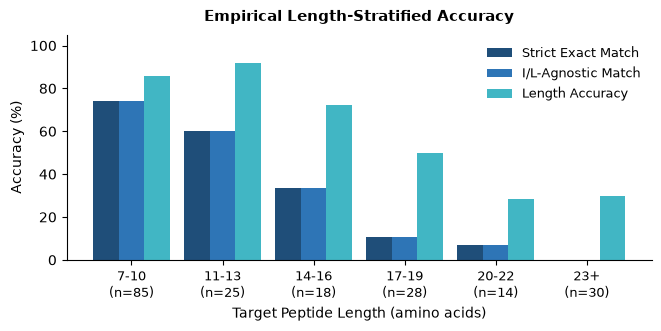

In [8]:
# Compute length stratification directly from user's results_df
def get_length_bin(l):
    if l <= 10: return "7-10"
    elif l <= 13: return "11-13"
    elif l <= 16: return "14-16"
    elif l <= 19: return "17-19"
    elif l <= 22: return "20-22"
    else: return "23+"

results_df["length_bin"] = results_df["target_length"].apply(get_length_bin)
bin_order = ["7-10", "11-13", "14-16", "17-19", "20-22", "23+"]
bin_summary = results_df.groupby("length_bin").agg(
    exact_acc=("exact_match", "mean"),
    il_acc=("exact_match_il", "mean"),
    len_acc=("exact_match", lambda s: np.mean(results_df.loc[s.index, "target_length"] == results_df.loc[s.index, "pred_length"])),
    count=("exact_match", "count"),
).reindex([b for b in bin_order if b in results_df["length_bin"].values])

fig, ax = plt.subplots(figsize=(6.5, 3.2), layout="constrained")
x = np.arange(len(bin_summary))
width = 0.28

ax.bar(x - width, bin_summary["exact_acc"] * 100, width, label="Strict Exact Match", color="#1F4E79")
ax.bar(x, bin_summary["il_acc"] * 100, width, label="I/L-Agnostic Match", color="#2E75B6")
ax.bar(x + width, bin_summary["len_acc"] * 100, width, label="Length Accuracy", color="#41B6C4")

ax.set_xticks(x)
ax.set_xticklabels([f"{b}\n(n={c})" for b, c in zip(bin_summary.index, bin_summary["count"])], fontsize=9)
ax.set_xlabel("Target Peptide Length (amino acids)", fontsize=10)
ax.set_ylabel("Accuracy (%)", fontsize=10)
ax.set_ylim(0, 105)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.title("Empirical Length-Stratified Accuracy", fontsize=11, fontweight="bold", pad=10)
plt.show()

### 8.2. Interactive Spectrum Fragment Mirror Plot
Inspect the raw experimental centroid MS/MS spectrum against the theoretical $b/y$ fragment ion ladder generated from the model's prediction.

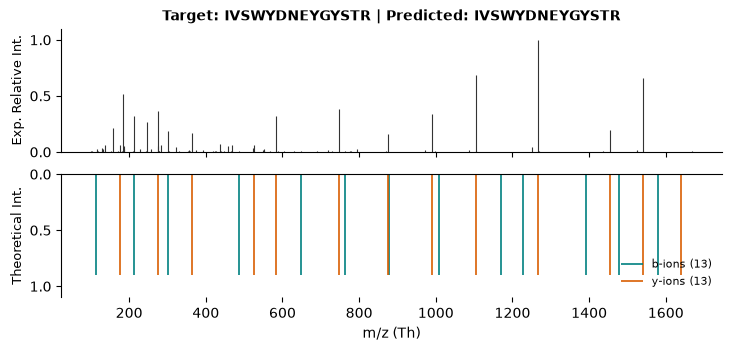

In [9]:
# Select a correctly sequenced spectrum from the batch to inspect
correct_indices = results_df[results_df["exact_match"]].index.tolist()
selected_idx = correct_indices[0] if correct_indices else 0

sample_record = eval_dataset[selected_idx]
pred_seq = results_df.loc[selected_idx, "prediction"]
tgt_seq = results_df.loc[selected_idx, "target"]

raw_mz = np.asarray(sample_record["mz_array"], dtype=np.float32)
raw_it = np.asarray(sample_record["intensity_array"], dtype=np.float32)
norm_it = raw_it / raw_it.max().clip(min=1e-7)

# Compute theoretical b and y fragment ions
tokens = parse_peptide(pred_seq)
b_masses, y_masses = [], []
cur_b = 0.0
for t in tokens[:-1]:
    cur_b += AA_MASSES_DICT.get(t, 100.0)
    b_masses.append(cur_b + M_H)

cur_y = M_H2O
for t in reversed(tokens[1:]):
    cur_y += AA_MASSES_DICT.get(t, 100.0)
    y_masses.append(cur_y + M_H)

fig, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(7.2, 3.4), sharex=True, layout="constrained")

# Experimental Spectrum (Top)
ax_top.vlines(raw_mz, 0, norm_it, color="#333333", lw=0.8)
ax_top.set_ylabel("Exp. Relative Int.", fontsize=9)
ax_top.set_ylim(0, 1.1)
ax_top.spines["top"].set_visible(False)
ax_top.spines["right"].set_visible(False)
ax_top.set_title(f"Target: {tgt_seq} | Predicted: {pred_seq}", fontsize=10, fontweight="bold")

# Theoretical Fragment Ladder (Bottom)
ax_bot.vlines(b_masses, 0, 0.9, color="#008080", lw=1.2, label=f"b-ions ({len(b_masses)})")
ax_bot.vlines(y_masses, 0, 0.9, color="#D95F02", lw=1.2, label=f"y-ions ({len(y_masses)})")
ax_bot.set_ylabel("Theoretical Int.", fontsize=9)
ax_bot.set_xlabel("m/z (Th)", fontsize=10)
ax_bot.set_ylim(0, 1.1)
ax_bot.invert_yaxis()
ax_bot.spines["bottom"].set_visible(False)
ax_bot.spines["right"].set_visible(False)
ax_bot.legend(frameon=False, loc="lower right", fontsize=8)
plt.show()

### 8.3. Posterior Confidence Reliability Curve
Inspect whether posterior confidence scores accurately reflect empirical prediction correctness.

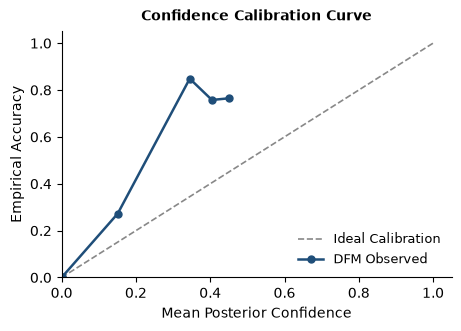

In [10]:
# Quantile binning over confidence scores
try:
    results_df["conf_bin"] = pd.qcut(results_df["confidence_score"], q=min(6, len(results_df)//10), duplicates="drop")
    calib_df = results_df.groupby("conf_bin", observed=False).agg(
        mean_conf=("confidence_score", "mean"),
        emp_acc=("exact_match_il", "mean"),
        count=("exact_match", "count"),
    ).reset_index()

    fig, ax = plt.subplots(figsize=(4.5, 3.2), layout="constrained")
    ax.plot([0, 1], [0, 1], "--", color="#888888", lw=1.2, label="Ideal Calibration")
    ax.plot(calib_df["mean_conf"].clip(0, 1), calib_df["emp_acc"], marker="o", color="#1F4E79", lw=1.8, ms=5, label="DFM Observed")
    ax.set_xlabel("Mean Posterior Confidence", fontsize=10)
    ax.set_ylabel("Empirical Accuracy", fontsize=10)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(0, 1.05)
    ax.legend(frameon=False, loc="lower right", fontsize=9)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.title("Confidence Calibration Curve", fontsize=10, fontweight="bold", pad=8)
    plt.show()
except Exception as e:
    print(f"Skipping calibration curve plot: {e}")

### 8.4. Precursor Mass Error Distribution ($\Delta\text{ppm}$)
Validates the physical fidelity of generated peptide sequences relative to precursor mass measurements.

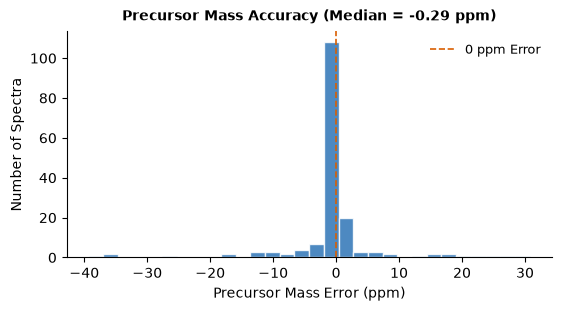

In [11]:
# Compute precursor mass error for all predictions
def calculate_seq_mass(seq_str):
    toks = parse_peptide(seq_str)
    return sum(AA_MASSES_DICT.get(t, 100.0) for t in toks) + M_H2O

pred_masses = [calculate_seq_mass(s) for s in results_df["prediction"]]
target_masses = [eval_dataset[i]["precursor_mass"] for i in range(len(results_df))]
delta_ppm = np.array([(pm - tm) / tm * 1e6 for pm, tm in zip(pred_masses, target_masses)])

fig, ax = plt.subplots(figsize=(5.5, 3.0), layout="constrained")
clipped_ppm = delta_ppm[np.abs(delta_ppm) <= 100]
ax.hist(clipped_ppm, bins=30, color="#2E75B6", edgecolor="white", alpha=0.85)
ax.axvline(0, color="#D95F02", linestyle="--", lw=1.2, label="0 ppm Error")
ax.set_xlabel("Precursor Mass Error (ppm)", fontsize=10)
ax.set_ylabel("Number of Spectra", fontsize=10)
ax.legend(frameon=False, loc="upper right", fontsize=9)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.title(f"Precursor Mass Accuracy (Median = {np.median(delta_ppm):.2f} ppm)", fontsize=10, fontweight="bold", pad=8)
plt.show()

---
### Summary & Next Steps
You have successfully loaded Discrete Flow Matching, performed *de novo* peptide sequencing on experimental MS/MS spectra from the Nine-Species benchmark, and generated interactive diagnostic figures.

To experiment further:
- Try changing `SELECTED_MODEL` in Section 2 to **MassIVE-KB 28M Foundation**.
- Adjust `guidance_scale` ($\gamma$) or `top_k_lengths` in Section 3 to observe trade-offs between precision and speed.
- Scale `NUM_SPECTRA` in Section 4 to 1,000 or 5,000 to benchmark larger batches.